# Extracellular diffusion Monte Carlo calibration of WM tortuosity exponents

This standalone notebook tests the proposed WM extracellular tortuosity law **without using that law to generate the diffusion data**. It simulates extracellular Brownian walkers in periodic 3-D substrates containing impermeable spherical soma and parallel cylindrical neurites (aligned with z), with no CSF/free-water compartment.

Effective diffusivities are measured from displacement:

$$D_{\parallel}(t)=\langle\Delta z^2\rangle/(2t), \qquad D_{\perp}(t)=\langle\Delta x^2+\Delta y^2\rangle/(4t).$$

Only afterwards are the candidate laws tested:

$$D_{\parallel}\approx D_0\left(1-\frac{f_s}{1-f_n}\right)^a,$$

$$D_{\perp}\approx D_{\parallel}\left(1-\frac{f_n}{1-f_s}\right)^b.$$

Initial experiment: $D_0=2.2$ um2/ms, diffusion time 12 ms, neurite radius 0.5 um, $f_s=0.05:0.05:0.30$, $f_n=0.20:0.10:0.50$, and soma radius 3:1:8 um. The notebook also includes soma-only and neurite-only controls, convergence checks, checkpointing, time-dependence analysis, and mixed-substrate validation.

**Important:** this is a controlled proof-of-principle simulator. Finite-step endpoint rejection approximates reflecting boundaries only as the timestep becomes small, so timestep convergence is mandatory before scientific interpretation.

In [11]:
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_SEED = 12345
D0 = 2.2
T_MAX = 12.0
R_NEURITE = 0.5
F_SOMA_VALUES = np.arange(0.05, 0.30 + 1e-9, 0.05)
F_NEURITE_VALUES = np.arange(0.20, 0.50 + 1e-9, 0.10)
R_SOMA_VALUES = np.arange(3.0, 8.0 + 1e-9, 1.0)
SAVE_TIMES = np.array([1.0, 2.0, 4.0, 8.0, 12.0])
OUTDIR = Path("mc_tortuosity_outputs")
OUTDIR.mkdir(exist_ok=True)
print(F_SOMA_VALUES, F_NEURITE_VALUES, R_SOMA_VALUES)

[0.05 0.1  0.15 0.2  0.25 0.3 ] [0.2 0.3 0.4 0.5] [3. 4. 5. 6. 7. 8.]


## Geometry and collision helpers

Cylinders are infinite along z and periodic in x/y. Spheres are periodic in all three dimensions. Realised fractions are recorded because integer object counts discretise the requested fractions.

In [12]:
@dataclass
class Substrate:
    box_length: float
    r_neurite: float
    cylinder_xy: np.ndarray
    sphere_xyz: np.ndarray
    sphere_r: float
    substrate_type: str


def periodic_delta(delta, L):
    return delta - L * np.round(delta / L)


def inside_cylinders(points, centers, radius, L, chunk=256):
    if len(centers) == 0:
        return np.zeros(len(points), dtype=bool)
    out = np.zeros(len(points), dtype=bool); r2 = radius**2
    for j in range(0, len(centers), chunk):
        c = centers[j:j+chunk]
        dx = periodic_delta(points[:,None,0]-c[None,:,0], L)
        dy = periodic_delta(points[:,None,1]-c[None,:,1], L)
        out |= np.any(dx*dx+dy*dy < r2, axis=1)
    return out


def inside_spheres(points, centers, radius, L, chunk=128):
    if len(centers) == 0:
        return np.zeros(len(points), dtype=bool)
    out = np.zeros(len(points), dtype=bool); r2 = radius**2
    for j in range(0, len(centers), chunk):
        c = centers[j:j+chunk]
        d = periodic_delta(points[:,None,:]-c[None,:,:], L)
        out |= np.any(np.sum(d*d, axis=2) < r2, axis=1)
    return out


def inside_obstacles(points, sub):
    return inside_cylinders(points, sub.cylinder_xy, sub.r_neurite, sub.box_length) | inside_spheres(points, sub.sphere_xyz, sub.sphere_r, sub.box_length)


def cyl_clear_cyl(c, existing, r, L):
    if len(existing)==0: return True
    d=periodic_delta(existing-c,L)
    return np.all(np.sum(d*d,axis=1)>=(2*r)**2)

def cyl_clear_sph(c, spheres, rc, rs, L):
    if len(spheres)==0: return True
    d=periodic_delta(spheres[:,:2]-c,L)
    return np.all(np.sum(d*d,axis=1)>=(rc+rs)**2)

def sph_clear_sph(c, existing, r, L):
    if len(existing)==0: return True
    d=periodic_delta(existing-c,L)
    return np.all(np.sum(d*d,axis=1)>=(2*r)**2)

def sph_clear_cyl(c, cylinders, rs, rc, L):
    if len(cylinders)==0: return True
    d=periodic_delta(cylinders-c[:2],L)
    return np.all(np.sum(d*d,axis=1)>=(rs+rc)**2)

In [13]:
def make_substrate(f_soma, f_neurite, r_soma, *, box_length=40.0, r_neurite=0.5, seed=0, max_attempts=20000, substrate_type="mixed"):
    rng=np.random.default_rng(seed); L=float(box_length)
    n_cyl=int(round(f_neurite*L**2/(np.pi*r_neurite**2)))
    n_sph=0 if f_soma==0 else int(round(f_soma*L**3/((4/3)*np.pi*r_soma**3)))
    cylinders=[]; spheres=[]
    for i in range(n_sph):
        for attempt in range(max_attempts):
            c=rng.uniform(0,L,3)
            if sph_clear_sph(c,np.asarray(spheres),r_soma,L) and sph_clear_cyl(c,np.asarray(cylinders),r_soma,r_neurite,L):
                spheres.append(c); break
        else: raise RuntimeError(f"Sphere packing failed {i+1}/{n_sph}")
    for i in range(n_cyl):
        for attempt in range(max_attempts):
            c=rng.uniform(0,L,2)
            if cyl_clear_cyl(c,np.asarray(cylinders),r_neurite,L) and cyl_clear_sph(c,np.asarray(spheres),r_neurite,r_soma,L):
                cylinders.append(c); break
        else: raise RuntimeError(f"Cylinder packing failed {i+1}/{n_cyl}")
    cylinders=np.asarray(cylinders,float).reshape(-1,2); spheres=np.asarray(spheres,float).reshape(-1,3)
    fs=len(spheres)*(4/3)*np.pi*r_soma**3/L**3 if r_soma>0 else 0.0
    fn=len(cylinders)*np.pi*r_neurite**2/L**2
    return Substrate(L,r_neurite,cylinders,spheres,float(r_soma),substrate_type),fs,fn

## Brownian walker simulation

For each step, $\Delta x_i\sim N(0,2D_0\Delta t)$. Proposed endpoints inside an obstacle are rejected. Wrapped coordinates are used for collision detection while unwrapped cumulative displacement is retained for MSD. The approximation must be checked by decreasing $\Delta t$.

In [14]:
def initialise_walkers(sub,n,rng,batch=10000):
    parts=[]; count=0
    while count<n:
        x=rng.uniform(0,sub.box_length,size=(max(batch,n-count),3))
        x=x[~inside_obstacles(x,sub)]
        take=min(len(x),n-count)
        if take: parts.append(x[:take]); count+=take
    return np.vstack(parts)


def simulate_diffusion(sub, *, D0=2.2, t_max=12.0, dt=0.01, n_walkers=10000, save_times=(1,2,4,8,12), seed=0):
    rng=np.random.default_rng(seed)
    wrapped=initialise_walkers(sub,n_walkers,rng); disp=np.zeros_like(wrapped)
    n_steps=int(round(t_max/dt)); dt=t_max/n_steps; sd=np.sqrt(2*D0*dt)
    save_steps={int(round(t/dt)):t for t in save_times if 0<t<=t_max}
    rows=[]; rejected=0
    for step in range(1,n_steps+1):
        delta=rng.normal(0,sd,size=wrapped.shape)
        proposed=np.mod(wrapped+delta,sub.box_length)
        blocked=inside_obstacles(proposed,sub); acc=~blocked
        wrapped[acc]=proposed[acc]; disp[acc]+=delta[acc]; rejected+=blocked.sum()
        if step in save_steps:
            t=step*dt; dx2=disp[:,0]**2; dy2=disp[:,1]**2; dz2=disp[:,2]**2
            pc=dz2/(2*t); qc=(dx2+dy2)/(4*t)
            rows.append(dict(time_ms=t,D_parallel=pc.mean(),D_perp=qc.mean(),SE_parallel=pc.std(ddof=1)/np.sqrt(n_walkers),SE_perp=qc.std(ddof=1)/np.sqrt(n_walkers),rejection_fraction=rejected/(step*n_walkers),dt_ms=dt,n_walkers=n_walkers))
    return pd.DataFrame(rows)

## Mandatory convergence study

Run representative low/mid/high obstruction cases before production. Examine timestep, walker count, and box-size stability. The defaults are starting points, not pre-certified settings.

In [15]:
CONVERGENCE_CASES=[("low",0.05,0.20,5.0),("mid",0.15,0.30,5.0),("high",0.30,0.50,5.0)]
DT_VALUES=[0.04,0.02,0.01]
WALKER_VALUES=[2500,5000,10000]
BOX_VALUES=[30.0,40.0,50.0]
RUN_CONVERGENCE=True
conv=[]
if RUN_CONVERGENCE:
    for ci,(name,fs,fn,rs) in enumerate(CONVERGENCE_CASES):
        for L in BOX_VALUES:
            try: sub,fsr,fnr=make_substrate(fs,fn,rs,box_length=L,r_neurite=R_NEURITE,seed=BASE_SEED+ci*1000+int(L),substrate_type="convergence")
            except Exception as e: print("packing failed",name,L,e); continue
            for dt in DT_VALUES:
                for nw in WALKER_VALUES:
                    t0=time.time(); sim=simulate_diffusion(sub,D0=D0,t_max=T_MAX,dt=dt,n_walkers=nw,save_times=[12],seed=BASE_SEED+50000+ci)
                    row=sim.iloc[-1].to_dict(); row.update(case=name,box_length=L,f_soma_real=fsr,f_neurite_real=fnr,r_soma=rs,runtime_s=time.time()-t0); conv.append(row); print(row)
    convergence_df=pd.DataFrame(conv); convergence_df.to_csv(OUTDIR/"convergence_results.csv",index=False); display(convergence_df)
else: print("Set RUN_CONVERGENCE=True when ready")

{'time_ms': 12.0, 'D_parallel': 1.7912664405592484, 'D_perp': 1.5256450665477486, 'SE_parallel': 0.05116524351356791, 'SE_perp': 0.030214617395047418, 'rejection_fraction': 0.15429866666666667, 'dt_ms': 0.04, 'n_walkers': 2500.0, 'case': 'low', 'box_length': 30.0, 'f_soma_real': 0.05817764173314431, 'f_neurite_real': 0.1998401993533507, 'r_soma': 5.0, 'runtime_s': 1.433480978012085}
{'time_ms': 12.0, 'D_parallel': 1.7505839003577726, 'D_perp': 1.5563294049903642, 'SE_parallel': 0.03473925544499037, 'SE_perp': 0.02239689180861999, 'rejection_fraction': 0.15373733333333334, 'dt_ms': 0.04, 'n_walkers': 5000.0, 'case': 'low', 'box_length': 30.0, 'f_soma_real': 0.05817764173314431, 'f_neurite_real': 0.1998401993533507, 'r_soma': 5.0, 'runtime_s': 1.8997089862823486}
{'time_ms': 12.0, 'D_parallel': 1.810132973321635, 'D_perp': 1.5257919336000025, 'SE_parallel': 0.02557371169427116, 'SE_perp': 0.015769793429805425, 'rejection_fraction': 0.15358733333333333, 'dt_ms': 0.04, 'n_walkers': 10000.0

,time_ms,D_parallel,D_perp,SE_parallel,SE_perp,rejection_fraction,dt_ms,n_walkers,case,box_length,f_soma_real,f_neurite_real,r_soma,runtime_s
0,12.0,1.791266,1.525645,0.051165,0.030215,0.154299,0.04,2500.0,low,30.0,0.058178,0.199840,5.0,1.433481
1,12.0,1.750584,1.556329,0.034739,0.022397,0.153737,0.04,5000.0,low,30.0,0.058178,0.199840,5.0,1.899709
2,12.0,1.810133,1.525792,0.025574,0.015770,0.153587,0.04,10000.0,low,30.0,0.058178,0.199840,5.0,3.399843
3,12.0,1.799409,1.535299,0.052193,0.031303,0.120851,0.02,2500.0,low,30.0,0.058178,0.199840,5.0,2.326433
4,12.0,1.827426,1.531527,0.037736,0.022203,0.120155,0.02,5000.0,low,30.0,0.058178,0.199840,5.0,3.424057
5,12.0,1.934737,1.502668,0.027754,0.015483,0.119752,0.02,10000.0,low,30.0,0.058178,0.199840,5.0,6.731630
6,12.0,1.895532,1.525634,0.056091,0.031261,0.088888,0.01,2500.0,low,30.0,0.058178,0.199840,5.0,4.717002
7,12.0,1.888653,1.550323,0.038298,0.022255,0.089166,0.01,5000.0,low,30.0,0.058178,0.199840,5.0,6.962583
8,12.0,1.953845,1.548345,0.027618,0.015646,0.088462,0.01,10000.0,low,30.0,0.058178,0.199840,5.0,14.005144
9,12.0,1.814966,1.550686,0.051957,0.031517,0.145268,0.04,2500.0,low,40.0,0.049087,0.199786,5.0,2.122014


In [24]:
# =============================================================================
# TIMESTEP x WALKER CONVERGENCE TEST
# =============================================================================
#
# Purpose:
#   Jointly test:
#       1. timestep convergence
#       2. walker-number convergence
#       3. Monte-Carlo variability across independent walker seeds
#
# IMPORTANT:
#   The substrate geometry is generated ONCE and held fixed.
#   Only the Brownian walker realisation changes between repeats.
# =============================================================================

CONVERGENCE_CASES = [
    ("low", 0.05, 0.20, 5.0),
]

DT_VALUES = [
    0.00125,
    0.000625,
]

WALKER_VALUES = [
    20000,
]

# Independent Brownian walker repeats
N_REPEATS = 4

BOX_VALUES = [
    40.0,
]

RUN_CONVERGENCE = True

conv = []


if RUN_CONVERGENCE:

    for ci, (name, fs, fn, rs) in enumerate(
        CONVERGENCE_CASES
    ):

        for L in BOX_VALUES:

            # =========================================================
            # Construct ONE geometry
            # =========================================================
            #
            # This seed stays fixed.
            #
            # Therefore differences between repeats below arise from
            # Brownian walker sampling, NOT different obstacle geometry.
            # =========================================================

            geometry_seed = (
                BASE_SEED
                + ci * 1000
                + int(L)
            )

            try:

                sub, fsr, fnr = make_substrate(
                    fs,
                    fn,
                    rs,
                    box_length=L,
                    r_neurite=R_NEURITE,
                    seed=geometry_seed,
                    substrate_type="convergence",
                )

            except Exception as e:

                print(
                    "packing failed",
                    name,
                    L,
                    e,
                )

                continue


            print(
                "\nGeometry successfully generated"
            )

            print(
                f"target fs={fs:.4f}, "
                f"realised fs={fsr:.4f}"
            )

            print(
                f"target fn={fn:.4f}, "
                f"realised fn={fnr:.4f}"
            )


            # =========================================================
            # Numerical convergence grid
            # =========================================================

            for dt in DT_VALUES:

                for nw in WALKER_VALUES:

                    for repeat in range(
                        N_REPEATS
                    ):

                        # ---------------------------------------------
                        # Different Brownian seed for every repeat
                        # ---------------------------------------------

                        walker_seed = (
                            BASE_SEED
                            + 50000
                            + ci * 10000
                            + repeat * 1000
                        )

                        print(
                            f"\nRunning: "
                            f"case={name}, "
                            f"L={L}, "
                            f"dt={dt}, "
                            f"walkers={nw}, "
                            f"repeat={repeat + 1}/{N_REPEATS}"
                        )

                        t0 = time.time()

                        sim = simulate_diffusion(
                            sub,
                            D0=D0,
                            t_max=T_MAX,
                            dt=dt,
                            n_walkers=nw,
                            save_times=[12],
                            seed=walker_seed,
                        )

                        row = (
                            sim.iloc[-1]
                            .to_dict()
                        )

                        row.update(

                            case=name,

                            repeat=repeat,

                            geometry_seed=
                                geometry_seed,

                            walker_seed=
                                walker_seed,

                            box_length=L,

                            f_soma_real=
                                fsr,

                            f_neurite_real=
                                fnr,

                            r_soma=
                                rs,

                            runtime_s=
                                time.time()
                                - t0,
                        )

                        conv.append(
                            row
                        )

                        print(
                            row
                        )


    # =============================================================
    # Save all individual runs
    # =============================================================

    convergence_df = pd.DataFrame(
        conv
    )

    convergence_df.to_csv(
        OUTDIR
        / "dt_walker_convergence_results.csv",
        index=False,
    )

    display(
        convergence_df
    )


else:

    print(
        "Set RUN_CONVERGENCE=True when ready"
    )


Geometry successfully generated
target fs=0.0500, realised fs=0.0491
target fn=0.2000, realised fn=0.1998

Running: case=low, L=40.0, dt=0.00125, walkers=20000, repeat=1/4
{'time_ms': 12.0, 'D_parallel': 2.076288292162336, 'D_perp': 1.6283094698716636, 'SE_parallel': 0.020668345313984093, 'SE_perp': 0.011648951784513509, 'rejection_fraction': 0.032182578125, 'dt_ms': 0.00125, 'n_walkers': 20000.0, 'case': 'low', 'repeat': 0, 'geometry_seed': 12385, 'walker_seed': 62345, 'box_length': 40.0, 'f_soma_real': 0.04908738521234052, 'f_neurite_real': 0.19978565781422591, 'r_soma': 5.0, 'runtime_s': 632.5608189105988}

Running: case=low, L=40.0, dt=0.00125, walkers=20000, repeat=2/4
{'time_ms': 12.0, 'D_parallel': 2.0596020200818055, 'D_perp': 1.6537322848733806, 'SE_parallel': 0.021065321062603982, 'SE_perp': 0.012010613654314337, 'rejection_fraction': 0.0321469375, 'dt_ms': 0.00125, 'n_walkers': 20000.0, 'case': 'low', 'repeat': 1, 'geometry_seed': 12385, 'walker_seed': 63345, 'box_length': 

,time_ms,D_parallel,D_perp,SE_parallel,SE_perp,rejection_fraction,dt_ms,n_walkers,case,repeat,geometry_seed,walker_seed,box_length,f_soma_real,f_neurite_real,r_soma,runtime_s
0,12.0,2.076288,1.628309,0.020668,0.011649,0.032183,0.001250,20000.0,low,0,12385,62345,40.0,0.049087,0.199786,5.0,632.560819
1,12.0,2.059602,1.653732,0.021065,0.012011,0.032147,0.001250,20000.0,low,1,12385,63345,40.0,0.049087,0.199786,5.0,649.758112
2,12.0,2.024396,1.655839,0.020223,0.012070,0.032106,0.001250,20000.0,low,2,12385,64345,40.0,0.049087,0.199786,5.0,645.925401
3,12.0,2.078161,1.646199,0.021262,0.011707,0.032148,0.001250,20000.0,low,3,12385,65345,40.0,0.049087,0.199786,5.0,643.603705
4,12.0,2.116156,1.660858,0.021289,0.011849,0.022816,0.000625,20000.0,low,0,12385,62345,40.0,0.049087,0.199786,5.0,1225.300850
5,12.0,2.060942,1.665525,0.020858,0.012029,0.022845,0.000625,20000.0,low,1,12385,63345,40.0,0.049087,0.199786,5.0,1264.704389
6,12.0,2.068080,1.676897,0.020540,0.012185,0.022893,0.000625,20000.0,low,2,12385,64345,40.0,0.049087,0.199786,5.0,1266.163726
7,12.0,2.090887,1.677821,0.021028,0.011915,0.022907,0.000625,20000.0,low,3,12385,65345,40.0,0.049087,0.199786,5.0,1298.501440


In [25]:
# =============================================================================
# SUMMARISE REPEATS FOR EACH dt x WALKER COMBINATION
# =============================================================================

convergence_summary = (

    convergence_df

    .groupby(
        [
            "dt_ms",
            "n_walkers",
        ]
    )

    .agg(

        n_repeats=(
            "D_parallel",
            "size",
        ),

        # ---------------------------------------------------------
        # Parallel diffusivity
        # ---------------------------------------------------------

        D_parallel_mean=(
            "D_parallel",
            "mean",
        ),

        D_parallel_sd=(
            "D_parallel",
            "std",
        ),

        D_parallel_min=(
            "D_parallel",
            "min",
        ),

        D_parallel_max=(
            "D_parallel",
            "max",
        ),

        # ---------------------------------------------------------
        # Perpendicular diffusivity
        # ---------------------------------------------------------

        D_perp_mean=(
            "D_perp",
            "mean",
        ),

        D_perp_sd=(
            "D_perp",
            "std",
        ),

        D_perp_min=(
            "D_perp",
            "min",
        ),

        D_perp_max=(
            "D_perp",
            "max",
        ),

        # ---------------------------------------------------------
        # Other diagnostics
        # ---------------------------------------------------------

        rejection_mean=(
            "rejection_fraction",
            "mean",
        ),

        runtime_mean_s=(
            "runtime_s",
            "mean",
        ),

    )

    .reset_index()
)


display(
    convergence_summary
)

,dt_ms,n_walkers,n_repeats,D_parallel_mean,D_parallel_sd,D_parallel_min,D_parallel_max,D_perp_mean,D_perp_sd,D_perp_min,D_perp_max,rejection_mean,runtime_mean_s
0,0.000625,20000.0,4,2.084016,0.024943,2.060942,2.116156,1.670275,0.008407,1.660858,1.677821,0.022865,1263.667601
1,0.001250,20000.0,4,2.059612,0.024916,2.024396,2.078161,1.646020,0.012511,1.628309,1.655839,0.032146,642.962009


,dt_ms,D_parallel,SE_parallel,D_perp,SE_perp,rejection_fraction,runtime_s
0,0.0025,2.022382,0.027992,1.602701,0.016424,0.044996,136.615648
1,0.0050,2.006275,0.028122,1.551113,0.015819,0.062876,68.056535
2,0.0100,1.989036,0.028123,1.544950,0.015813,0.086287,34.107020
3,0.0200,1.930305,0.027487,1.486880,0.015299,0.116230,17.068124
4,0.0400,1.830784,0.025955,1.530542,0.015526,0.148256,8.992700


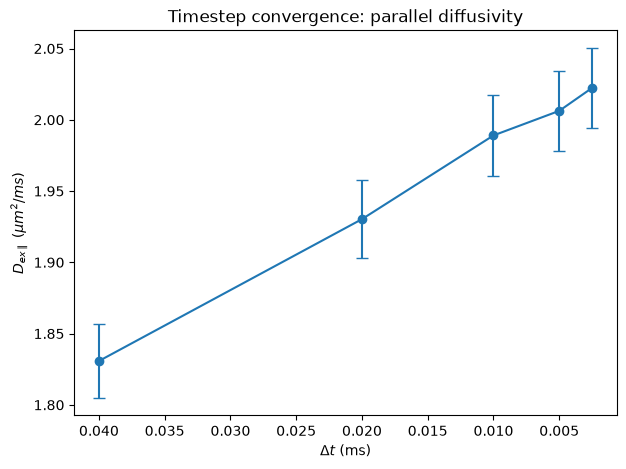

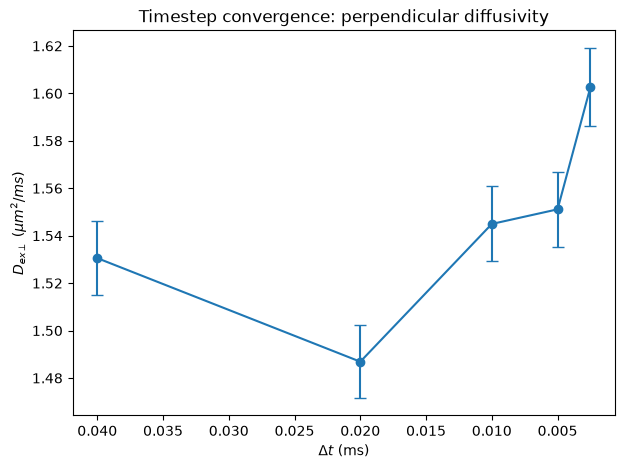

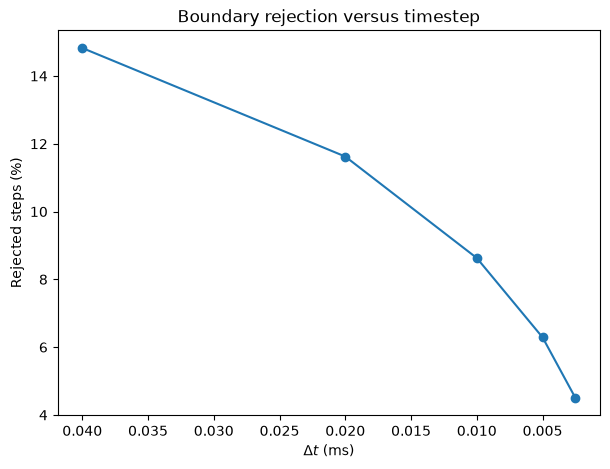

In [21]:
# =============================================================================
# PLOT TIMESTEP CONVERGENCE
# =============================================================================

convergence_sorted = (
    convergence_df
    .sort_values("dt_ms")
    .reset_index(drop=True)
)

display(
    convergence_sorted[
        [
            "dt_ms",
            "D_parallel",
            "SE_parallel",
            "D_perp",
            "SE_perp",
            "rejection_fraction",
            "runtime_s",
        ]
    ]
)


# -------------------------------------------------------------------------
# D_parallel
# -------------------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.errorbar(
    convergence_sorted["dt_ms"],
    convergence_sorted["D_parallel"],
    yerr=convergence_sorted["SE_parallel"],
    marker="o",
    capsize=4,
)

plt.xlabel(
    r"$\Delta t$ (ms)"
)

plt.ylabel(
    r"$D_{ex\parallel}$ ($\mu m^2/ms$)"
)

plt.title(
    "Timestep convergence: parallel diffusivity"
)

plt.gca().invert_xaxis()

plt.show()


# -------------------------------------------------------------------------
# D_perp
# -------------------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.errorbar(
    convergence_sorted["dt_ms"],
    convergence_sorted["D_perp"],
    yerr=convergence_sorted["SE_perp"],
    marker="o",
    capsize=4,
)

plt.xlabel(
    r"$\Delta t$ (ms)"
)

plt.ylabel(
    r"$D_{ex\perp}$ ($\mu m^2/ms$)"
)

plt.title(
    "Timestep convergence: perpendicular diffusivity"
)

plt.gca().invert_xaxis()

plt.show()


# -------------------------------------------------------------------------
# Rejected steps
# -------------------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    convergence_sorted["dt_ms"],
    100 * convergence_sorted["rejection_fraction"],
    marker="o",
)

plt.xlabel(
    r"$\Delta t$ (ms)"
)

plt.ylabel(
    "Rejected steps (%)"
)

plt.title(
    "Boundary rejection versus timestep"
)

plt.gca().invert_xaxis()

plt.show()

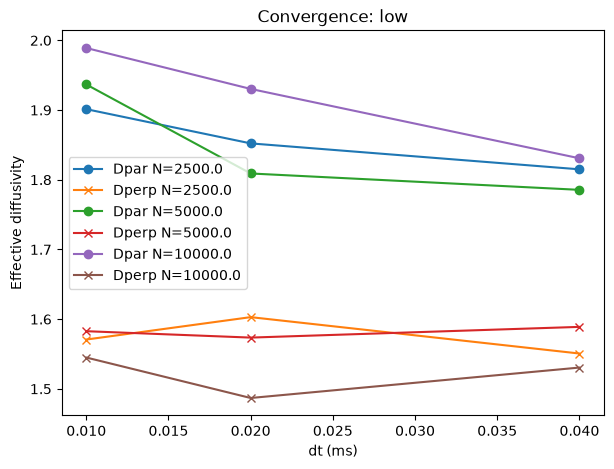

In [16]:
if "convergence_df" in globals() and len(convergence_df):
    for case in convergence_df.case.unique():
        fig,ax=plt.subplots(figsize=(7,5)); q0=convergence_df[(convergence_df.case==case)&(convergence_df.box_length==40)]
        for nw in sorted(q0.n_walkers.unique()):
            q=q0[q0.n_walkers==nw].sort_values("dt_ms")
            ax.plot(q.dt_ms,q.D_parallel,marker="o",label=f"Dpar N={nw}"); ax.plot(q.dt_ms,q.D_perp,marker="x",label=f"Dperp N={nw}")
        ax.set(xlabel="dt (ms)",ylabel="Effective diffusivity",title=f"Convergence: {case}"); ax.legend(); plt.show()

In [17]:
PRODUCTION_DT=0.01
PRODUCTION_N_WALKERS=10000
PRODUCTION_BOX_LENGTH=40.0
print("1D step SD =",np.sqrt(2*D0*PRODUCTION_DT),"um")

1D step SD = 0.20976176963403032 um


## Experimental design

144 mixed substrates + 36 soma-only controls + 4 neurite-only controls = 184 total. The controls isolate each obstruction mechanism before mixed-substrate validation.

In [18]:
rows=[]; sid=0
for fs in F_SOMA_VALUES:
    for fn in F_NEURITE_VALUES:
        for rs in R_SOMA_VALUES:
            rows.append(dict(substrate_id=sid,substrate_type="mixed",f_soma_target=float(fs),f_neurite_target=float(fn),r_soma=float(rs))); sid+=1
for fs in F_SOMA_VALUES:
    for rs in R_SOMA_VALUES:
        rows.append(dict(substrate_id=sid,substrate_type="soma_only",f_soma_target=float(fs),f_neurite_target=0.0,r_soma=float(rs))); sid+=1
for fn in F_NEURITE_VALUES:
    rows.append(dict(substrate_id=sid,substrate_type="neurite_only",f_soma_target=0.0,f_neurite_target=float(fn),r_soma=0.0)); sid+=1
design=pd.DataFrame(rows); design["f_extra_target"]=1-design.f_soma_target-design.f_neurite_target
print(design.substrate_type.value_counts()); print("Total",len(design)); display(design)

substrate_type
mixed           144
soma_only        36
neurite_only      4
Name: count, dtype: int64
Total 184


,substrate_id,substrate_type,f_soma_target,f_neurite_target,r_soma,f_extra_target
0,0,mixed,0.05,0.2,3.0,0.75
1,1,mixed,0.05,0.2,4.0,0.75
2,2,mixed,0.05,0.2,5.0,0.75
3,3,mixed,0.05,0.2,6.0,0.75
4,4,mixed,0.05,0.2,7.0,0.75
...,...,...,...,...,...,...
179,179,soma_only,0.30,0.0,8.0,0.70
180,180,neurite_only,0.00,0.2,0.0,0.80
181,181,neurite_only,0.00,0.3,0.0,0.70
182,182,neurite_only,0.00,0.4,0.0,0.60


## Production runner with checkpointing

Set `RUN_PRODUCTION=True` only after convergence settings have been reviewed. Every saved timepoint is checkpointed. Packing failures are retained rather than silently altering geometry.

In [19]:
RESULTS_FILE=OUTDIR/"mc_substrate_results.csv"
RUN_PRODUCTION=False
existing=pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()
completed=set(existing.loc[existing.status=="ok","substrate_id"].astype(int)) if len(existing) else set()
out=existing.to_dict("records") if len(existing) else []
if RUN_PRODUCTION:
    for _,spec in design.iterrows():
        sid=int(spec.substrate_id)
        if sid in completed: continue
        print(f"[{sid+1}/{len(design)}] {spec.substrate_type} fs={spec.f_soma_target:.2f} fn={spec.f_neurite_target:.2f} rs={spec.r_soma:.1f}")
        t0=time.time()
        try:
            sub,fsr,fnr=make_substrate(spec.f_soma_target,spec.f_neurite_target,max(spec.r_soma,1e-9),box_length=PRODUCTION_BOX_LENGTH,r_neurite=R_NEURITE,seed=BASE_SEED+10*sid,substrate_type=spec.substrate_type)
            sim=simulate_diffusion(sub,D0=D0,t_max=T_MAX,dt=PRODUCTION_DT,n_walkers=PRODUCTION_N_WALKERS,save_times=SAVE_TIMES,seed=BASE_SEED+10*sid+1)
            runtime=time.time()-t0
            for _,s in sim.iterrows():
                out.append({**spec.to_dict(),"f_soma_real":fsr,"f_neurite_real":fnr,"f_extra_real":1-fsr-fnr,**s.to_dict(),"box_length":PRODUCTION_BOX_LENGTH,"runtime_s":runtime,"status":"ok"})
            completed.add(sid)
        except Exception as e:
            out.append({**spec.to_dict(),"status":"failed","error":repr(e),"runtime_s":time.time()-t0}); print("FAILED",e)
        pd.DataFrame(out).to_csv(RESULTS_FILE,index=False)
else: print("Set RUN_PRODUCTION=True after convergence testing")

Set RUN_PRODUCTION=True after convergence testing


# Analysis: controls first, mixed validation second

Soma-only controls estimate $a$ from $D/D_0=(1-f_s)^a$. Neurite-only controls estimate $b$ from $D_\perp/D_\parallel=(1-f_n)^b$ and directly test whether $D_\parallel\approx D_0$. Mixed substrates are then an independent validation set for the multiplicative law.

In [ ]:
def slope0(x,y):
    x=np.asarray(x,float); y=np.asarray(y,float); return np.sum(x*y)/np.sum(x*x)

if RESULTS_FILE.exists():
    results=pd.read_csv(RESULTS_FILE); ok=results[results.status=="ok"].copy(); final12=ok[np.isclose(ok.time_ms,12)].copy()
    soma=final12[final12.substrate_type=="soma_only"].copy(); neur=final12[final12.substrate_type=="neurite_only"].copy(); mixed=final12[final12.substrate_type=="mixed"].copy()
    soma["a_implied"]=np.log(soma.D_parallel/D0)/np.log(1-soma.f_soma_real)
    a_control=slope0(np.log(1-soma.f_soma_real),np.log(soma.D_parallel/D0))
    neur["b_implied"]=np.log(neur.D_perp/neur.D_parallel)/np.log(1-neur.f_neurite_real)
    b_control=slope0(np.log(1-neur.f_neurite_real),np.log(neur.D_perp/neur.D_parallel))
    print("a_control",a_control,"b_control",b_control)
    print("neurite-only Dpar/D0",(neur.D_parallel/D0).to_numpy())
    display(soma); display(neur)
else: print("No production results yet")

In [ ]:
if "mixed" in globals() and len(mixed):
    mixed["S"]=1-mixed.f_soma_real/(1-mixed.f_neurite_real)
    mixed["N"]=1-mixed.f_neurite_real/(1-mixed.f_soma_real)
    mixed["a_implied"]=np.log(mixed.D_parallel/D0)/np.log(mixed.S)
    mixed["b_implied"]=np.log(mixed.D_perp/mixed.D_parallel)/np.log(mixed.N)
    mixed["D_parallel_pred"]=D0*mixed.S**a_control
    mixed["D_perp_pred"]=mixed.D_parallel_pred*mixed.N**b_control
    a_mixed=slope0(np.log(mixed.S),np.log(mixed.D_parallel/D0)); b_mixed=slope0(np.log(mixed.N),np.log(mixed.D_perp/mixed.D_parallel))
    print("controls a,b",a_control,b_control); print("mixed descriptive a,b",a_mixed,b_mixed)
    print("validation RMSE par",np.sqrt(np.mean((mixed.D_parallel_pred-mixed.D_parallel)**2)))
    print("validation RMSE perp",np.sqrt(np.mean((mixed.D_perp_pred-mixed.D_perp)**2)))

In [ ]:
if "mixed" in globals() and len(mixed):
    for obs,pred,title in [("D_parallel","D_parallel_pred","Parallel"),("D_perp","D_perp_pred","Perpendicular")]:
        fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(mixed[obs],mixed[pred],alpha=.65); lo=min(mixed[obs].min(),mixed[pred].min()); hi=max(mixed[obs].max(),mixed[pred].max()); ax.plot([lo,hi],[lo,hi],"--"); ax.set(xlabel="Monte Carlo",ylabel="Control-calibrated prediction",title=title); plt.show()

    a_rs=mixed.groupby("r_soma").a_implied.agg(["mean","std","median","count"]).reset_index(); display(a_rs)
    fig,ax=plt.subplots(figsize=(7,5)); ax.errorbar(a_rs.r_soma,a_rs["mean"],yerr=a_rs["std"],marker="o",capsize=3); ax.axhline(a_control,ls="--"); ax.set(xlabel="Soma radius (um)",ylabel="Implied a",title="a versus soma radius"); plt.show()

    b_fn=mixed.groupby("f_neurite_target").b_implied.agg(["mean","std","median"]).reset_index(); display(b_fn)
    fig,ax=plt.subplots(figsize=(7,5)); ax.errorbar(b_fn.f_neurite_target,b_fn["mean"],yerr=b_fn["std"],marker="o",capsize=3); ax.axhline(b_control,ls="--"); ax.set(xlabel="f_neurite",ylabel="Implied b",title="b versus neurite fraction"); plt.show()

## Diffusion-time dependence and neurite-radius robustness

The saved intermediate times allow a/b to be inspected versus diffusion time. After the main run, repeat a small representative subset at neurite radii 0.25 and 0.4 um rather than immediately rerunning all 184 substrates.

In [ ]:
if "ok" in globals() and len(ok):
    tr=[]
    for t,q in ok.groupby("time_ms"):
        m=q[q.substrate_type=="mixed"].copy()
        if len(m):
            S=1-m.f_soma_real/(1-m.f_neurite_real); N=1-m.f_neurite_real/(1-m.f_soma_real)
            tr.append(dict(time_ms=t,a=slope0(np.log(S),np.log(m.D_parallel/D0)),b=slope0(np.log(N),np.log(m.D_perp/m.D_parallel))))
    exponent_time=pd.DataFrame(tr); display(exponent_time)
    fig,ax=plt.subplots(figsize=(7,5)); ax.plot(exponent_time.time_ms,exponent_time.a,marker="o",label="a"); ax.plot(exponent_time.time_ms,exponent_time.b,marker="o",label="b"); ax.set(xlabel="Diffusion time (ms)",ylabel="Global implied exponent",title="Time dependence"); ax.legend(); plt.show()

NEURITE_RADIUS_ROBUSTNESS=[0.25,0.40,0.50]
ROBUSTNESS_CASES=pd.DataFrame([
    {"f_soma":0.05,"f_neurite":0.20,"r_soma":5.0},
    {"f_soma":0.15,"f_neurite":0.30,"r_soma":5.0},
    {"f_soma":0.25,"f_neurite":0.40,"r_soma":5.0},
    {"f_soma":0.30,"f_neurite":0.50,"r_soma":5.0},
]); display(ROBUSTNESS_CASES)

# Interpretation checklist

1. Confirm timestep convergence by decreasing dt.  
2. Confirm walker convergence and Monte-Carlo SE.  
3. Confirm box-size stability.  
4. Inspect packing failures and realised fractions.  
5. Test whether neurite-only parallel diffusion remains near D0.  
6. Test whether soma-only a depends on soma radius/fraction.  
7. Test whether neurite-only b depends on neurite fraction.  
8. Use control-derived a,b to predict mixed substrates before fitting mixed data.  
9. Inspect residual structure rather than relying only on RMSE.  
10. Inspect diffusion-time dependence.  
11. Repeat a representative subset at smaller neurite radii.  

A clean result would be approximately stable control-derived exponents that predict mixed-substrate Monte-Carlo diffusivities with little structured residual error. If that does not occur, the simulation is still useful: it identifies which assumption in the proposed tortuosity law needs refinement.